# 📦 01 · Exploración y limpieza de datos
**Proyecto:** Segmentación de clientes (RFM + K-Means) y canasta de compras (Apriori)
**Dataset:** *Online Retail II* — ventas de una tienda online del Reino Unido (dic-2009 a dic-2011).

### Contenido
1. Carga de datos crudos
2. Diagnóstico de calidad
3. Limpieza paso a paso
4. Guardado de la tabla limpia
5. Exploración visual de las ventas
6. Exportación de agregados para el dashboard

In [1]:
# Configuración general e importaciones
from pathlib import Path
import sqlite3
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB = ROOT / "data" / "retail.db"
PROCESADOS = ROOT / "data" / "processed"
PROCESADOS.mkdir(parents=True, exist_ok=True)

PALETA = ["#6C5CE7", "#00CEC9", "#FD79A8", "#FDCB6E", "#74B9FF", "#55EFC4", "#E17055", "#A29BFE"]
COLOR_SEGMENTO = {
    "Campeones": "#FDCB6E", "Leales": "#00B894", "Nuevos / Prometedores": "#74B9FF",
    "Necesitan atención": "#A29BFE", "En Riesgo": "#E17055", "Perdidos / Hibernando": "#636E72",
}
px.defaults.template = "plotly_white"
pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].width = 1100
px.defaults.color_discrete_sequence = PALETA


def estilo(fig, titulo, alto=450):
    """Aplica el mismo formato visual a todos los gráficos del proyecto."""
    fig.update_layout(title=dict(text=f"<b>{titulo}</b>", x=0.01), height=alto,
                      font=dict(family="Segoe UI, Arial", size=13),
                      margin=dict(l=40, r=20, t=70, b=40), legend_title_text="")
    return fig


con = sqlite3.connect(DB)
print(f"Proyecto en: {ROOT}")

Proyecto en: C:\Users\eduar\retail-customer-segmentation-rfm


## 1 · Carga de datos crudos
Los datos del Excel ya fueron cargados a SQLite con `scripts/load_data.py`.

In [2]:
# Carga de la tabla cruda desde SQLite
df = pd.read_sql("SELECT * FROM retail_sales", con, parse_dates=["InvoiceDate"])
df["StockCode"] = df["StockCode"].astype(str)
df["Customer ID"] = df["Customer ID"].astype("Int64")
print(f"Registros: {len(df):,} · Columnas: {df.shape[1]}")
print(f"Periodo: {df['InvoiceDate'].min():%d-%m-%Y} → {df['InvoiceDate'].max():%d-%m-%Y}")
df.head()

Registros: 1,067,371 · Columnas: 8
Periodo: 01-12-2009 → 09-12-2011


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom


## 2 · Diagnóstico de calidad
Antes de limpiar, medimos cuántos registros tienen problemas.

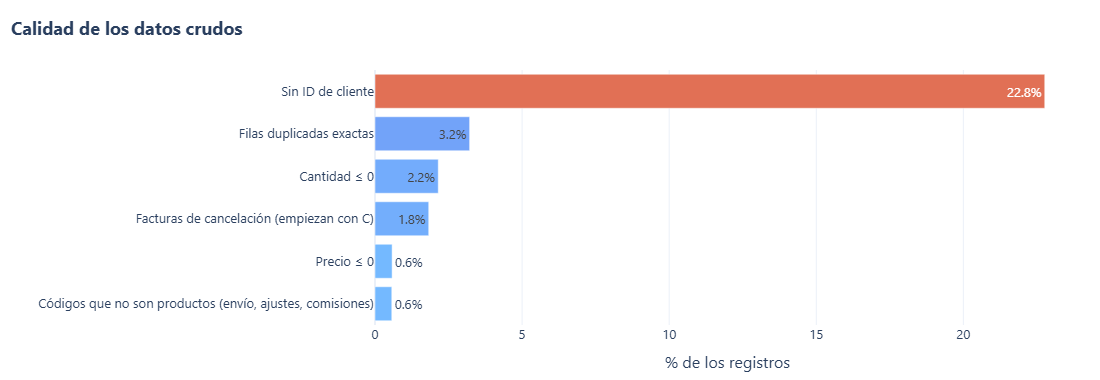

,Problema,Registros,% del total
0,Sin ID de cliente,243007,22.77
1,Facturas de cancelación (empiezan con C),19494,1.83
2,Cantidad ≤ 0,22950,2.15
3,Precio ≤ 0,6207,0.58
4,"Códigos que no son productos (envío, ajustes, ...",6093,0.57
5,Filas duplicadas exactas,34335,3.22


In [3]:
# Conteo de problemas de calidad en los datos crudos
es_cancelacion = df["Invoice"].astype(str).str.startswith("C")
es_producto = df["StockCode"].str.match(r"^\d{5}", na=False)

diagnostico = pd.DataFrame({
    "Problema": ["Sin ID de cliente", "Facturas de cancelación (empiezan con C)", "Cantidad ≤ 0",
                 "Precio ≤ 0", "Códigos que no son productos (envío, ajustes, comisiones)", "Filas duplicadas exactas"],
    "Registros": [df["Customer ID"].isna().sum(), es_cancelacion.sum(), (df["Quantity"] <= 0).sum(),
                  (df["Price"] <= 0).sum(), (~es_producto).sum(), df.duplicated().sum()],
})
diagnostico["% del total"] = diagnostico["Registros"] / len(df) * 100

fig = px.bar(diagnostico.sort_values("% del total"), x="% del total", y="Problema", orientation="h",
             text=diagnostico.sort_values("% del total")["% del total"].map("{:.1f}%".format),
             color="% del total", color_continuous_scale=["#74B9FF", "#6C5CE7", "#E17055"])
fig.update_layout(coloraxis_showscale=False, yaxis_title="", xaxis_title="% de los registros")
estilo(fig, "Calidad de los datos crudos", 380).show()
diagnostico

## 3 · Limpieza paso a paso
Reglas aplicadas:
1. Quitar registros **sin ID de cliente** (no se pueden asignar a nadie en RFM).
2. Quitar **códigos que no son productos** (`POST`, `D`, `M`, `BANK CHARGES`…): se conservan solo los que empiezan con 5 dígitos.
3. Quitar **duplicados exactos**.
4. Quitar **cancelaciones** y registros con cantidad o precio inválidos.
5. Quitar las **compras que fueron devueltas**: se emparejan con su cancelación por cliente, producto y cantidad. Así evitamos clientes con gasto inflado (por ejemplo, el cliente 12346 compraba y devolvía el mismo pedido de £77k).

Registros originales: 1,067,371  →  registros limpios: 769,725 (72.1%)


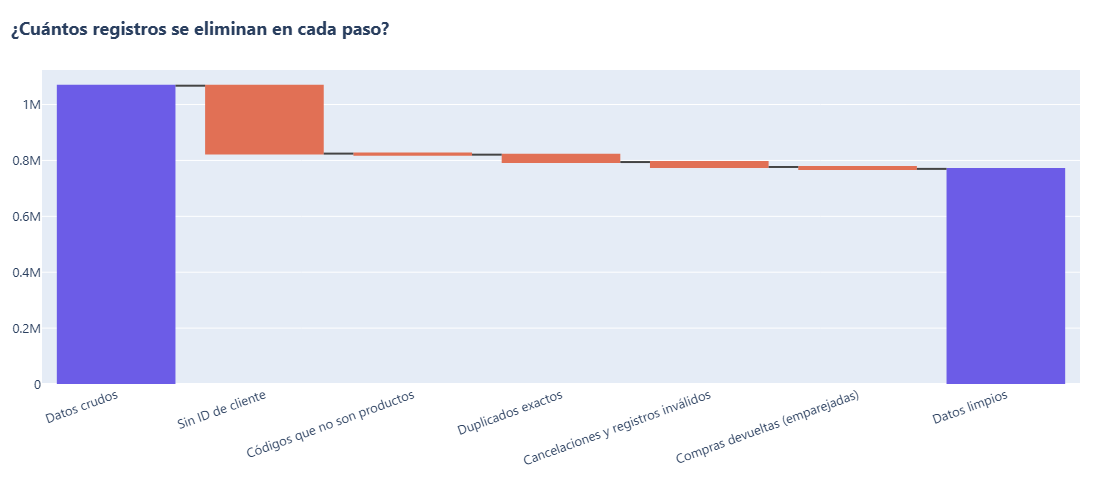

,Paso,Filas eliminadas
0,Sin ID de cliente,243007
1,Códigos que no son productos,3738
2,Duplicados exactos,26403
3,Cancelaciones y registros inválidos,17646
4,Compras devueltas (emparejadas),6852


In [4]:
# Limpieza de datos con registro de filas eliminadas en cada paso
pasos = []
d = df.copy()

def registrar(nombre, antes, despues):
    pasos.append({"Paso": nombre, "Filas eliminadas": antes - despues})

n = len(d); d = d[d["Customer ID"].notna()].copy()
registrar("Sin ID de cliente", n, len(d))
n = len(d); d = d[d["StockCode"].str.match(r"^\d{5}", na=False)]
registrar("Códigos que no son productos", n, len(d))
n = len(d); d = d.drop_duplicates()
registrar("Duplicados exactos", n, len(d))

d["Customer ID"] = d["Customer ID"].astype(int).astype(str)
cancel_mask = d["Invoice"].astype(str).str.startswith("C")
compras = d[~cancel_mask & (d["Quantity"] > 0) & (d["Price"] > 0)].sort_values("InvoiceDate")
cancel = d[cancel_mask].sort_values("InvoiceDate")
registrar("Cancelaciones y registros inválidos", len(d), len(compras))

claves = ["Customer ID", "StockCode", "Cantidad"]
c = cancel.assign(Cantidad=-cancel["Quantity"])[claves].copy()
c["orden"] = c.groupby(claves).cumcount()
c["devuelta"] = True
compras = compras.assign(Cantidad=compras["Quantity"])
compras["orden"] = compras.groupby(claves).cumcount()
marcadas = compras.merge(c, on=claves + ["orden"], how="left")
limpio = marcadas[marcadas["devuelta"].isna()].drop(columns=["Cantidad", "orden", "devuelta"]).copy()
registrar("Compras devueltas (emparejadas)", len(compras), len(limpio))

limpio["Ingreso"] = (limpio["Quantity"] * limpio["Price"]).round(2)
limpio = limpio.reset_index(drop=True)

resumen = pd.DataFrame(pasos)
print(f"Registros originales: {len(df):,}  →  registros limpios: {len(limpio):,} ({len(limpio)/len(df):.1%})")

fig = go.Figure(go.Waterfall(
    x=["Datos crudos"] + resumen["Paso"].tolist() + ["Datos limpios"],
    y=[len(df)] + (-resumen["Filas eliminadas"]).tolist() + [0],
    measure=["absolute"] + ["relative"] * len(resumen) + ["total"],
    increasing_marker_color="#00B894", decreasing_marker_color="#E17055", totals_marker_color="#6C5CE7"))
fig.update_layout(xaxis_tickangle=-20)
estilo(fig, "¿Cuántos registros se eliminan en cada paso?", 480).show()
resumen

## 4 · Guardado de la tabla limpia
La tabla `retail_sales_clean` será la base de los notebooks 02 y 03.

In [5]:
# Guardado de la tabla limpia en SQLite
a_guardar = limpio.copy()
a_guardar["InvoiceDate"] = a_guardar["InvoiceDate"].dt.strftime("%Y-%m-%d %H:%M:%S")
a_guardar.to_sql("retail_sales_clean", con, if_exists="replace", index=False, chunksize=50_000)
print(f"Tabla retail_sales_clean guardada con {len(a_guardar):,} filas")

Tabla retail_sales_clean guardada con 769,725 filas


## 5 · Exploración visual de las ventas

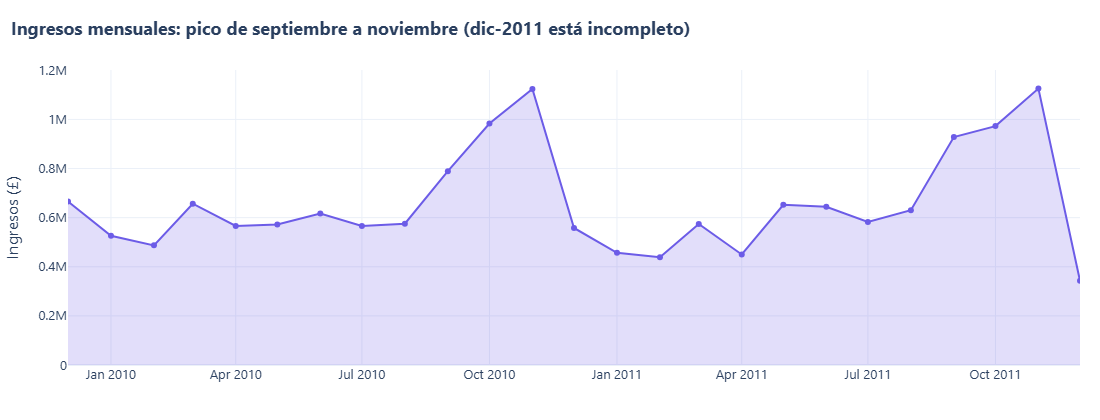

In [6]:
# Ingresos mensuales
limpio["Mes"] = limpio["InvoiceDate"].dt.to_period("M").dt.to_timestamp()
mensual = limpio.groupby("Mes").agg(Ingresos=("Ingreso", "sum"), Facturas=("Invoice", "nunique")).reset_index()

fig = px.area(mensual, x="Mes", y="Ingresos", markers=True)
fig.update_traces(line_color="#6C5CE7", fillcolor="rgba(108,92,231,0.2)")
fig.update_layout(yaxis_title="Ingresos (£)", xaxis_title="")
estilo(fig, "Ingresos mensuales: pico de septiembre a noviembre (dic-2011 está incompleto)", 420).show()

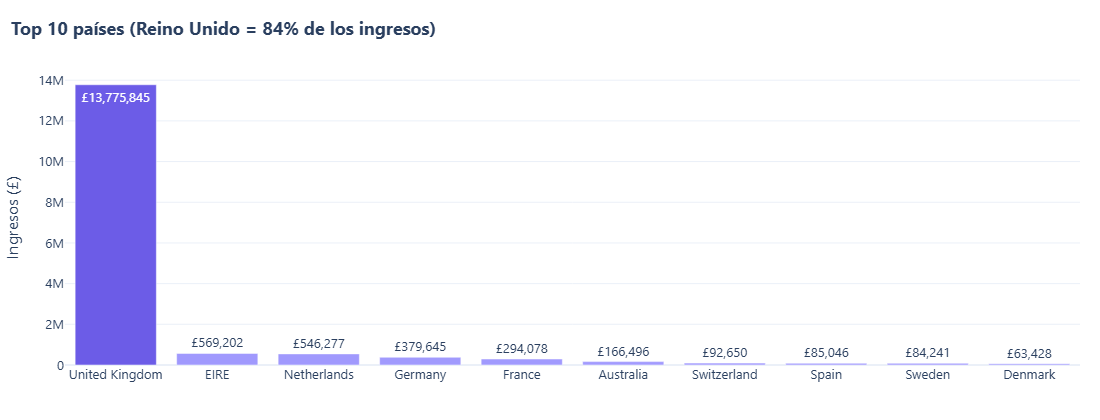

In [7]:
# Ingresos por país
por_pais = limpio.groupby("Country")["Ingreso"].sum().sort_values(ascending=False)
top = por_pais.head(10).reset_index()
fig = px.bar(top, x="Country", y="Ingreso", text=top["Ingreso"].map("£{:,.0f}".format), color="Ingreso",
             color_continuous_scale=["#A29BFE", "#6C5CE7"])
fig.update_layout(coloraxis_showscale=False, xaxis_title="", yaxis_title="Ingresos (£)")
estilo(fig, f"Top 10 países (Reino Unido = {por_pais.iloc[0]/por_pais.sum():.0%} de los ingresos)", 420).show()

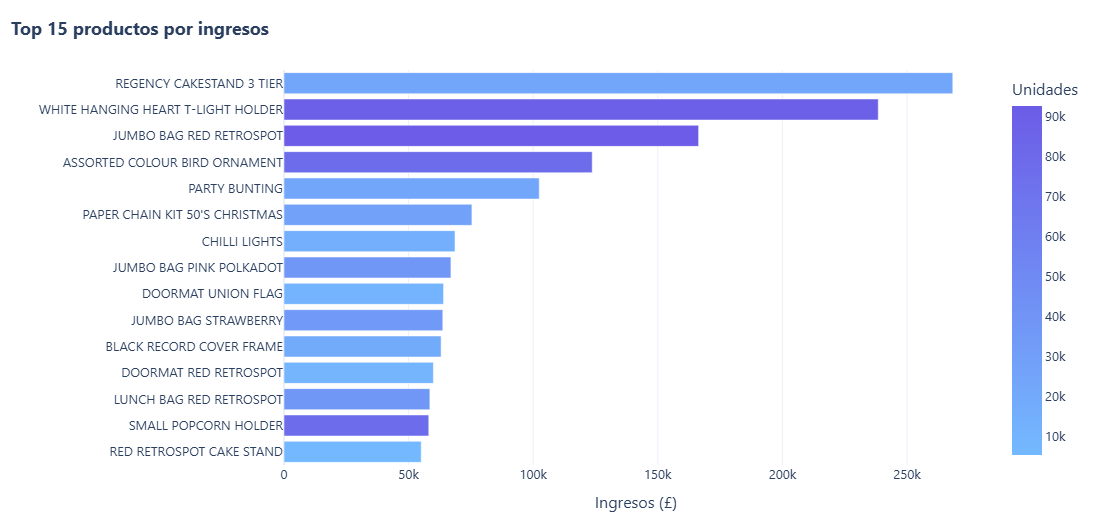

In [8]:
# Productos más rentables
nombre = limpio.dropna(subset=["Description"]).groupby("StockCode")["Description"].agg(lambda s: s.mode().iat[0]).str.strip()
productos = limpio.groupby("StockCode").agg(Ingresos=("Ingreso", "sum"), Unidades=("Quantity", "sum")).reset_index()
productos["Producto"] = productos["StockCode"].map(nombre)
productos = productos.sort_values("Ingresos", ascending=False)

top15 = productos.head(15).sort_values("Ingresos")
fig = px.bar(top15, x="Ingresos", y="Producto", orientation="h", color="Unidades",
             color_continuous_scale=["#74B9FF", "#6C5CE7"], hover_data=["Unidades"])
fig.update_layout(yaxis_title="", xaxis_title="Ingresos (£)")
estilo(fig, "Top 15 productos por ingresos", 520).show()

C:\Users\eduar\AppData\Local\Temp\ipykernel_79272\1536644393.py:3: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  limpio["DiaNum"] = limpio["InvoiceDate"].dt.dayofweek


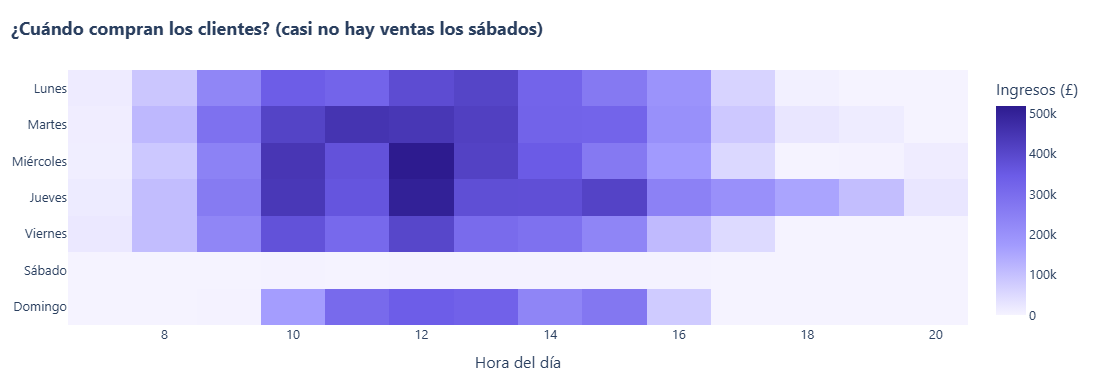

In [9]:
# Patrón de ventas por día de la semana y hora
dias = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
limpio["DiaNum"] = limpio["InvoiceDate"].dt.dayofweek
limpio["Hora"] = limpio["InvoiceDate"].dt.hour
dia_hora = limpio.groupby(["DiaNum", "Hora"])["Ingreso"].sum().reset_index()
pivote = dia_hora.pivot(index="DiaNum", columns="Hora", values="Ingreso").reindex(range(7)).fillna(0)
pivote.index = dias

fig = px.imshow(pivote, aspect="auto", color_continuous_scale=["#F5F3FF", "#A29BFE", "#6C5CE7", "#2D1B8F"],
                labels=dict(x="Hora del día", y="", color="Ingresos (£)"))
estilo(fig, "¿Cuándo compran los clientes? (casi no hay ventas los sábados)", 380).show()

## 6 · Exportación de agregados para el dashboard
Se guardan tablas pequeñas, así el dashboard carga rápido y no necesita la base de datos de 200 MB.

In [10]:
# Exportación de tablas agregadas a data/processed
mensual_pais = (limpio.assign(Mes=limpio["InvoiceDate"].dt.to_period("M").astype(str))
                .groupby(["Mes", "Country"]).agg(Ingresos=("Ingreso", "sum"), Facturas=("Invoice", "nunique"),
                                                  Clientes=("Customer ID", "nunique"), Unidades=("Quantity", "sum"))
                .reset_index().rename(columns={"Country": "Pais"}))
mensual_pais.to_csv(PROCESADOS / "ventas_mensuales.csv", index=False)

productos.head(100)[["Producto", "StockCode", "Ingresos", "Unidades"]].to_csv(PROCESADOS / "top_productos.csv", index=False)

dia_hora["Dia"] = dia_hora["DiaNum"].map(dict(enumerate(dias)))
dia_hora.to_csv(PROCESADOS / "ventas_dia_hora.csv", index=False)

print("Archivos exportados:", *[p.name for p in sorted(PROCESADOS.glob("*.csv"))], sep="\n · ")

Archivos exportados:
 · reglas_asociacion.csv
 · rfm_clusters.csv
 · top_productos.csv
 · ventas_dia_hora.csv
 · ventas_mensuales.csv


In [11]:
# Hallazgos clave del análisis exploratorio
mejor_mes = mensual.loc[mensual["Ingresos"].idxmax()]
print(f"💷 Ingresos totales: £{limpio['Ingreso'].sum():,.0f}")
print(f"👥 Clientes únicos: {limpio['Customer ID'].nunique():,}")
print(f"🧾 Facturas: {limpio['Invoice'].nunique():,}")
print(f"🇬🇧 Peso del Reino Unido: {por_pais.iloc[0]/por_pais.sum():.0%} de los ingresos")
print(f"📅 Mejor mes: {mejor_mes['Mes']:%B %Y} (£{mejor_mes['Ingresos']:,.0f})")
print(f"🏆 Producto estrella: {productos.iloc[0]['Producto']} (£{productos.iloc[0]['Ingresos']:,.0f})")

💷 Ingresos totales: £16,487,481
👥 Clientes únicos: 5,833
🧾 Facturas: 36,305
🇬🇧 Peso del Reino Unido: 84% de los ingresos
📅 Mejor mes: November 2011 (£1,125,903)
🏆 Producto estrella: REGENCY CAKESTAND 3 TIER (£268,375)
